# Golden window - which X range makes a batch fail QC, with statistical evidence

**Golden** = every Y inside `config.GOLDEN_SPEC` (Kappa 8-10, Viscosity 700-800, confirmed 2026-10-28).
Each X is tested for each **fail mode**, because one X can push two Y the same or opposite ways.

| Step | What | Why it is evidence |
|---|---|---|
| 1 | Fail rate per quintile of X (Wilson 95% CI) | shows *where* the fail rate jumps |
| 2 | Best cut + risk ratio + **permutation p** (outcome shuffled inside each month) | the p already pays for searching the cut, and the season cannot create it |
| 3 | **Mantel-Haenszel by month** + months that agree | same rule inside every month -> not a season effect |
| 4 | Cut from the early months, checked on the **later months** | the rule works on data it never saw |
| 5 | **Benjamini-Hochberg** q over all X | many X tested -> control false finds |
| 6 | Share on the bad side now, fail rate if moved; combined window check | what to control and what it is worth |

**Grade A** = 5 + 3 + 4 + every month agrees · **B** = 5 + (3 or 4) · **C** = 5 only · **-** = not significant.
Observational data: grade A is strong enough to propose a **trial**, not to prove cause.

Edit X in `config.FEATURES` / `config.GOLDEN_EXTRA`, the combined window in `config.GOLDEN_WINDOW_RULES`. No PI access.

In [37]:
import importlib
import pandas as pd

import config, data, golden, plots
for mod in (config, data, golden, plots):
    importlib.reload(mod)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 40)

## Step 0 - Data and why batches fail
A batch can fail more than one way, so the modes add up to more than `fail`.

In [38]:
df = golden.load_golden()
overall, by_month = golden.fail_modes(df)
display(overall)
display(by_month)

golden data: 654 batches with Kappa + Viscosity (2026-05-09 .. 2026-10-18), golden 251 (38%)


,batches,share
fail,403.0,0.616
kappa_high,335.0,0.512
kappa_low,1.0,0.002
visc_high,166.0,0.254
visc_low,21.0,0.032


,n,fail,kappa_high,kappa_low,visc_high,visc_low
month,,,,,,
2026-05,66,0.35,0.33,0.00,0.08,0.00
2026-06,97,0.29,0.26,0.00,0.00,0.03
2026-07,111,0.71,0.63,0.00,0.32,0.00
2026-08,138,0.79,0.52,0.01,0.60,0.02
2026-09,153,0.76,0.68,0.00,0.27,0.03
2026-10,89,0.54,0.47,0.00,0.02,0.11


## Outliers of X
Setting: `config.GOLDEN_OUTLIER` = `None` (keep all, default) / `"2sd"` / `"iqr3"`, removed **one X at a time** and per digester.
- Table 1: how many values each method would remove (high `skew` -> 2 SD is a poor rule, it only cuts the long side).
- Table 2 (**sensitivity**): the same threshold test with no / 2 SD / 3 IQR removal for the window X. If the cut, fail rates and months barely move, the result does not come from outliers.

In [39]:
print("GOLDEN_OUTLIER =", config.GOLDEN_OUTLIER, "| by digester:", config.GOLDEN_OUTLIER_BY_DIGESTER)
display(golden.outlier_report(df))
for col, _, _ in config.GOLDEN_WINDOW_RULES:
    print(f"Sensitivity - {golden.golden_features(df).get(col, col)} (Fail QC any)")
    display(golden.sensitivity(df, col, "fail"))

GOLDEN_OUTLIER = None | by digester: True


,n,skew,min,median,max,removed_2sd,removed_iqr3
X,,,,,,,
Alkali conc 1,654,0.1,34.782,36.745,38.770,12,0
P-factor,654,1.1,272.726,337.530,509.527,46,4
H&C minutes,654,3.9,15.000,35.000,115.000,10,4
WL / t chip,654,3.3,0.100,0.154,0.490,24,10
L:W,654,1.4,1.078,1.604,3.021,27,6
LP pressure,654,1.0,5.478,6.494,8.360,27,8
P-factor rate,654,-0.5,0.875,4.437,6.066,23,1
P-temp max,654,0.1,162.026,168.069,177.616,24,0
P-temp SP,494,0.7,162.000,163.000,166.000,8,0


Sensitivity - P-factor overshoot (Fail QC any)


,n,removed,bad side,fail bad / good,RR,p perm,MH RR,months agree
outliers,,,,,,,,
keep all,654,0,<= 64.3,78% / 52%,1.49,0.002,1.28,6/6
2sd,633,21,<= 64.67,77% / 51%,1.50,0.002,1.30,6/6
iqr3,629,25,<= 64.64,77% / 51%,1.51,0.002,1.30,6/6


Sensitivity - H-factor (Fail QC any)


,n,removed,bad side,fail bad / good,RR,p perm,MH RR,months agree
outliers,,,,,,,,
keep all,654,0,<= 333.8,78% / 53%,1.47,0.002,1.24,5/6
2sd,615,39,<= 334.3,77% / 54%,1.44,0.002,1.24,5/6
iqr3,614,40,<= 334.2,77% / 53%,1.46,0.002,1.25,5/6


## Steps 1-5 - Screen every X for every fail mode
How to read one row of the summary:
- **Bad side** `<= 64.3` -> batches with X at or below 64.3 fail more. *Cut 90% range* = how much the cut moves in a week-block bootstrap.
- **Fail % at bad side / Fail % at good side** -> both are FAIL rates: on the side that fails more (bad) and on the other side (good). **RR** = how many times more likely on the bad side.
- **p perm (q)** -> chance of a cut this strong by luck *within the same month*; q = after BH.
- **MH RR by month / Months agree** -> the effect after removing the season, and in how many months it points the same way.
- **Future fail % at bad / good side, Future p** -> cut found on the early months, fail rates in the later months.
- **Fail now -> if moved** -> fail rate if every bad-side batch moved to the good side (month-adjusted, upper estimate).

In [40]:
results = {}
for event in golden.OUTCOMES:
    res, _ = golden.screen(df, event, progress=False)
    results[event] = res
    print()
    print(f"===== {golden.OUTCOMES[event]}  (overall {df[event].mean():.0%}) =====")
    display(golden.summary(res))


===== Fail QC (any)  (overall 62%) =====


,X,Grade,Bad side,Cut 90% range,Fail % at bad side,Fail % at good side,RR [95% CI],p perm (q),MH RR by month,Months agree,Future fail % at bad side,Future fail % at good side,Future p,On bad side now,Fail now -> if moved
0,P-factor overshoot,A,<= 64.3,53.29 - 65.95,78% (<= 64.3),52% (> 64.3),1.49 [1.33-1.67],0.001 (0.008),1.28 (p 0.000),6/6,78%,62%,0.02,37%,62% -> 55%
1,H-factor,B,<= 333.8,320.3 - 455,78% (<= 333.8),53% (> 333.8),1.47 [1.31-1.64],0.001 (0.008),1.24 (p 0.000),5/6,69%,68%,0.51,35%,62% -> 56%
2,Alkali conc 1,B,<= 36.17,36.07 - 37.06,80% (<= 36.17),56% (> 36.17),1.44 [1.29-1.61],0.003 (0.017),1.45 (p 0.003),4/5,50%,69%,0.91,25%,62% -> 56%
3,LP pressure,B,<= 6.565,6.365 - 6.621,67% (<= 6.565),50% (> 6.565),1.34 [1.15-1.55],0.007 (0.030),1.23 (p 0.002),4/6,66%,75%,0.93,67%,62% -> 53%
4,P-temp SP,-,<= 163,163 - 164,81% (<= 163),44% (> 163),1.86 [1.57-2.19],0.053 (0.133),1.19 (p 0.078),4/4,77%,63%,0.04,59%,62% -> 55%
5,P-temp max,-,<= 166.9,165.2 - 167.9,76% (<= 166.9),54% (> 166.9),1.41 [1.26-1.58],0.054 (0.133),1.14 (p 0.028),4/5,86%,62%,0.00,35%,62% -> 59%
6,L:W,-,<= 1.568,1.415 - 1.816,71% (<= 1.568),55% (> 1.568),1.31 [1.16-1.47],0.055 (0.133),1.14 (p 0.028),5/6,68%,88%,0.95,43%,62% -> 58%
7,P-factor final,-,<= 400.7,399.4 - 491.8,78% (<= 400.7),58% (> 400.7),1.35 [1.20-1.52],0.069 (0.146),1.15 (p 0.074),2/2,100%,68%,0.32,18%,62% -> 60%
8,P-factor rate,-,<= 4.563,4.263 - 4.622,73% (<= 4.563),46% (> 4.563),1.59 [1.38-1.83],0.083 (0.157),1.15 (p 0.110),4/6,80%,58%,0.00,57%,62% -> 57%
9,WL / t chip,-,<= 0.1446,0.1377 - 0.1718,72% (<= 0.1446),57% (> 0.1446),1.27 [1.13-1.43],0.136 (0.231),1.10 (p 0.105),4/6,71%,67%,0.34,30%,62% -> 60%



===== Kappa high  (overall 51%) =====


,X,Grade,Bad side,Cut 90% range,Fail % at bad side,Fail % at good side,RR [95% CI],p perm (q),MH RR by month,Months agree,Future fail % at bad side,Future fail % at good side,Future p,On bad side now,Fail now -> if moved
0,P-factor overshoot,A,<= 64.3,62.19 - 72.66,64% (<= 64.3),44% (> 64.3),1.47 [1.27-1.70],0.001 (0.017),1.27 (p 0.001),6/6,72%,55%,0.01,37%,51% -> 46%
1,LP pressure,B,<= 6.565,6.361 - 6.623,57% (<= 6.565),39% (> 6.565),1.44 [1.20-1.74],0.005 (0.042),1.32 (p 0.001),4/6,60%,69%,0.89,67%,51% -> 42%
2,H-factor,-,<= 333.8,315 - 503.6,63% (<= 333.8),45% (> 333.8),1.42 [1.23-1.64],0.010 (0.057),1.23 (p 0.005),5/6,58%,64%,0.86,35%,51% -> 47%
3,P-factor,-,> 341.8,308.9 - 409.8,57% (> 341.8),47% (<= 341.8),1.22 [1.05-1.42],0.022 (0.093),1.31 (p 0.009),3/4,-,-,-,43%,51% -> 46%
4,P-temp max,-,<= 166.9,165.8 - 170.8,62% (<= 166.9),45% (> 166.9),1.38 [1.20-1.60],0.066 (0.224),1.16 (p 0.062),3/5,82%,54%,0.00,35%,51% -> 48%
5,P-factor rate,-,<= 4.563,4.339 - 4.723,60% (<= 4.563),40% (> 4.563),1.51 [1.28-1.79],0.132 (0.294),1.19 (p 0.126),4/6,74%,52%,0.00,57%,51% -> 47%
6,P-factor final,-,<= 400.7,396.3 - 500.4,63% (<= 400.7),49% (> 400.7),1.31 [1.11-1.54],0.146 (0.294),1.16 (p 0.198),2/2,67%,62%,0.68,18%,51% -> 50%
7,Alkali / t chip,-,<= 5.331,5.186 - 6.821,59% (<= 5.331),48% (> 5.331),1.23 [1.06-1.43],0.147 (0.294),1.13 (p 0.123),4/6,68%,59%,0.14,33%,51% -> 49%
8,WL / t chip,-,<= 0.1446,0.1389 - 0.1856,59% (<= 0.1446),48% (> 0.1446),1.24 [1.06-1.44],0.164 (0.294),1.13 (p 0.103),5/6,65%,59%,0.25,30%,51% -> 49%
9,P-temp SP,-,<= 163,163 - 164,67% (<= 163),40% (> 163),1.67 [1.38-2.02],0.173 (0.294),1.16 (p 0.204),3/4,70%,57%,0.07,59%,51% -> 46%



===== Viscosity high  (overall 25%) =====


,X,Grade,Bad side,Cut 90% range,Fail % at bad side,Fail % at good side,RR [95% CI],p perm (q),MH RR by month,Months agree,Future fail % at bad side,Future fail % at good side,Future p,On bad side now,Fail now -> if moved
0,P-factor rate,B,<= 4.411,4.291 - 4.561,41% (<= 4.411),11% (> 4.411),3.85 [2.76-5.36],0.001 (0.003),1.76 (p 0.000),4/6,25%,7%,0.00,48%,25% -> 18%
1,Prehyd minutes,B,> 70,70 - 75,32% (> 70),12% (<= 70),2.65 [1.79-3.92],0.001 (0.003),1.64 (p 0.011),3/5,15%,0%,0.19,68%,25% -> 17%
2,P-factor overshoot,B,<= 54.44,49.51 - 59.53,50% (<= 54.44),19% (> 54.44),2.57 [2.01-3.29],0.001 (0.003),1.55 (p 0.000),3/4,24%,11%,0.02,20%,25% -> 22%
3,H-factor,B,<= 333.8,326.1 - 502,43% (<= 333.8),16% (> 333.8),2.67 [2.05-3.48],0.001 (0.003),1.94 (p 0.000),4/6,18%,11%,0.11,35%,25% -> 18%
4,P-factor final,B,<= 425,398.1 - 451.5,41% (<= 425),14% (> 425),2.88 [2.16-3.84],0.001 (0.003),1.78 (p 0.000),4/5,56%,10%,0.00,43%,25% -> 18%
5,Alkali conc 1,B,<= 36.09,36.06 - 37.38,58% (<= 36.09),16% (> 36.09),3.62 [2.84-4.61],0.004 (0.011),1.98 (p 0.008),4/4,33%,13%,0.36,22%,25% -> 21%
6,P-factor,B,<= 354.8,325.2 - 379.2,32% (<= 354.8),8% (> 354.8),3.82 [2.31-6.32],0.005 (0.011),2.14 (p 0.007),3/4,22%,12%,0.12,72%,25% -> 14%
7,H&C minutes,B,<= 35,30 - 35,29% (<= 35),16% (> 35),1.84 [1.25-2.71],0.005 (0.011),1.70 (p 0.004),3/5,24%,12%,0.08,75%,25% -> 16%
8,P-temp max,B,<= 166.2,165.2 - 167.4,44% (<= 166.2),17% (> 166.2),2.51 [1.95-3.24],0.009 (0.017),1.40 (p 0.005),3/5,23%,9%,0.01,30%,25% -> 22%
9,P-temp SP,-,<= 163,162 - 163,41% (<= 163),6% (> 163),6.39 [3.71-10.99],0.030 (0.051),1.74 (p 0.073),4/4,13%,9%,0.32,59%,25% -> 19%



===== Viscosity low  (overall 3%) =====


,X,Grade,Bad side,Cut 90% range,Fail % at bad side,Fail % at good side,RR [95% CI],p perm (q),MH RR by month,Months agree,Future fail % at bad side,Future fail % at good side,Future p,On bad side now,Fail now -> if moved
0,P-factor,-,> 358,351.4 - 396.9,10% (> 358),1% (<= 358),9.56 [3.56-25.69],0.011 (0.161),6.99 (p 0.007),2/2,8%,0%,0.08,25%,3% -> 1%
1,P-factor final,-,> 479.5,431.9 - 508.9,11% (> 479.5),1% (<= 479.5),7.98 [3.29-19.38],0.019 (0.161),7.49 (p 0.014),1/2,0%,7%,1.00,20%,3% -> 2%
2,Prehyd minutes,-,> 75,75 - 85,5% (> 75),1% (<= 75),5.85 [1.74-19.69],0.058 (0.293),5.42 (p 0.075),4/5,8%,5%,0.30,51%,3% -> 2%
3,Alkali conc 1,-,> 37.28,36.54 - 37.92,10% (> 37.28),2% (<= 37.28),6.49 [2.75-15.33],0.069 (0.293),5.23 (p 0.074),1/2,0%,7%,1.00,20%,3% -> 2%
4,L:W,-,<= 1.532,1.444 - 1.669,6% (<= 1.532),2% (> 1.532),3.71 [1.52-9.07],0.118 (0.401),2.94 (p 0.044),3/6,8%,5%,0.39,35%,3% -> 2%
5,WL m3,-,> 14.26,12.86 - 14.86,7% (> 14.26),2% (<= 14.26),2.91 [1.24-6.87],0.174 (0.493),2.51 (p 0.030),4/6,0%,8%,1.00,17%,3% -> 2%
6,Chip weight,-,> 93.06,74.74 - 94,6% (> 93.06),2% (<= 93.06),2.90 [1.25-6.70],0.237 (0.575),2.06 (p 0.110),3/6,7%,7%,0.61,28%,3% -> 2%
7,P-factor overshoot,-,> 86.54,51.82 - 90.41,6% (> 86.54),3% (<= 86.54),2.34 [0.97-5.68],0.335 (0.618),2.30 (p 0.058),3/6,3%,10%,0.99,18%,3% -> 3%
8,LP pressure,-,<= 6.32,6.211 - 6.638,6% (<= 6.32),2% (> 6.32),2.46 [1.04-5.80],0.339 (0.618),1.84 (p 0.156),2/5,7%,8%,0.79,20%,3% -> 3%
9,H&C minutes,-,> 35,30 - 35,6% (> 35),2% (<= 35),2.78 [1.20-6.43],0.398 (0.618),1.48 (p 0.384),3/5,0%,8%,1.00,25%,3% -> 3%


### Step 1 picture - fail rate per quintile of the top X
Orange = bins on the bad side of the cut. Error bars = Wilson 95% CI. Bars that overlap the dashed line are not different from average.

  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\golden_curves_fail.png
  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\golden_curves_kappa_high.png
  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\golden_curves_visc_high.png


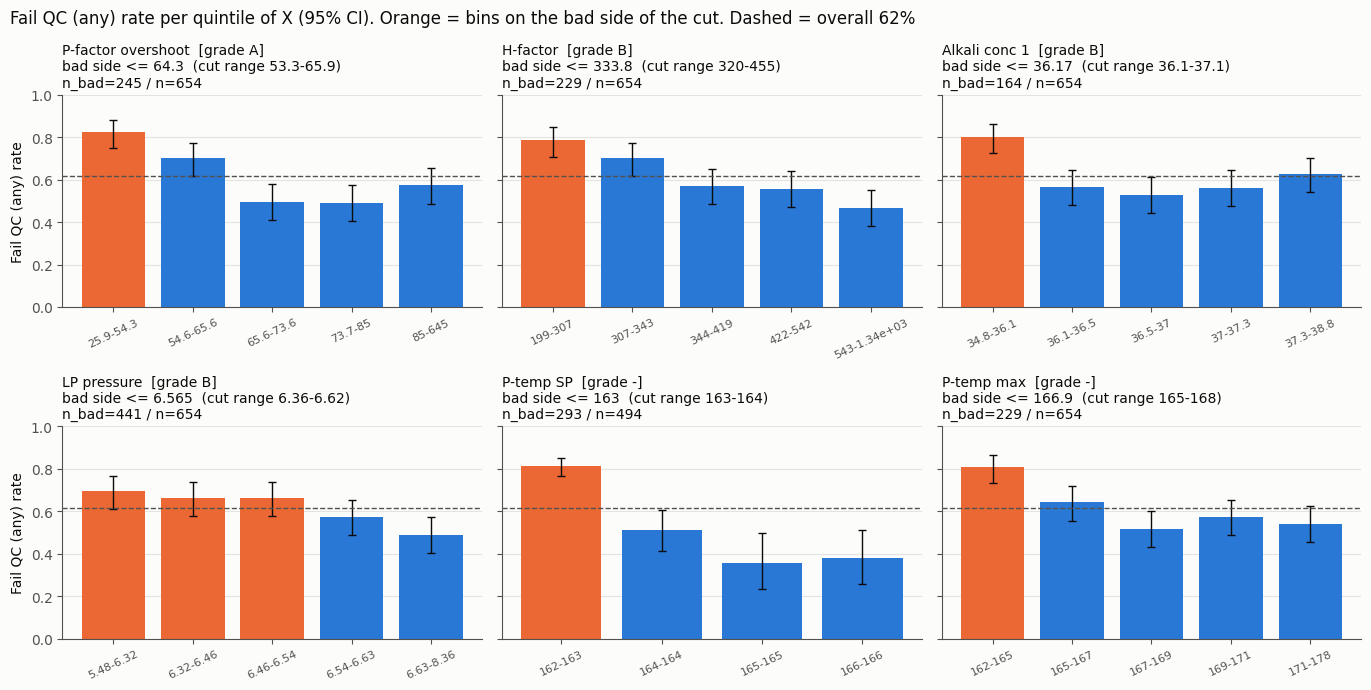

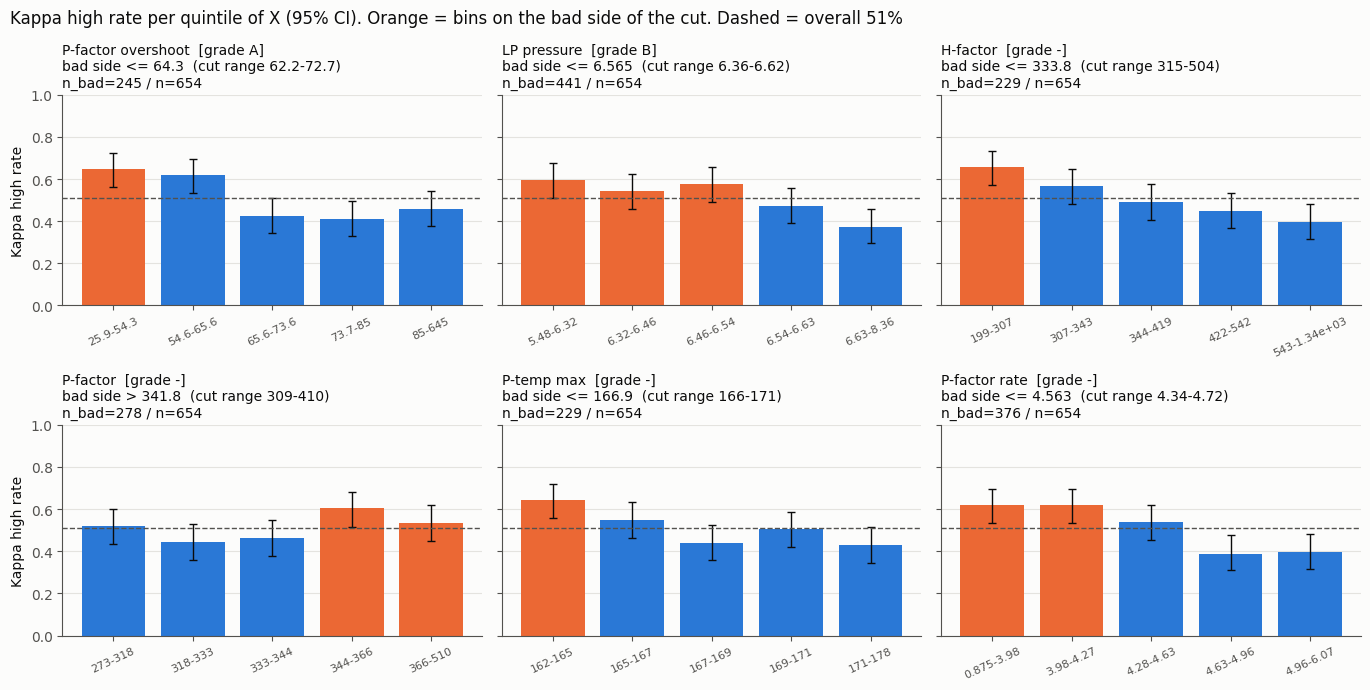

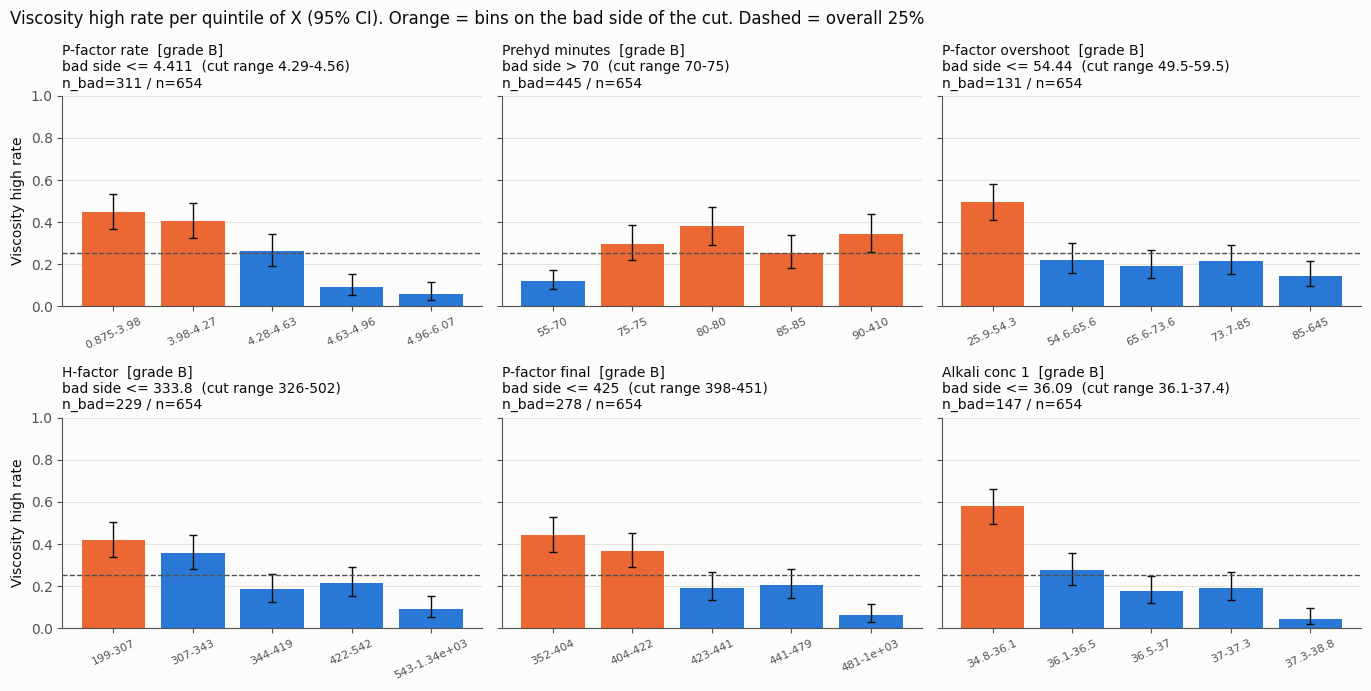

In [41]:
for event in ["fail", "kappa_high", "visc_high"]:
    plots.fail_curves(df, results[event], event)

  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\golden_counts_fail.png
  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\golden_counts_kappa_high.png
  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\golden_counts_visc_high.png


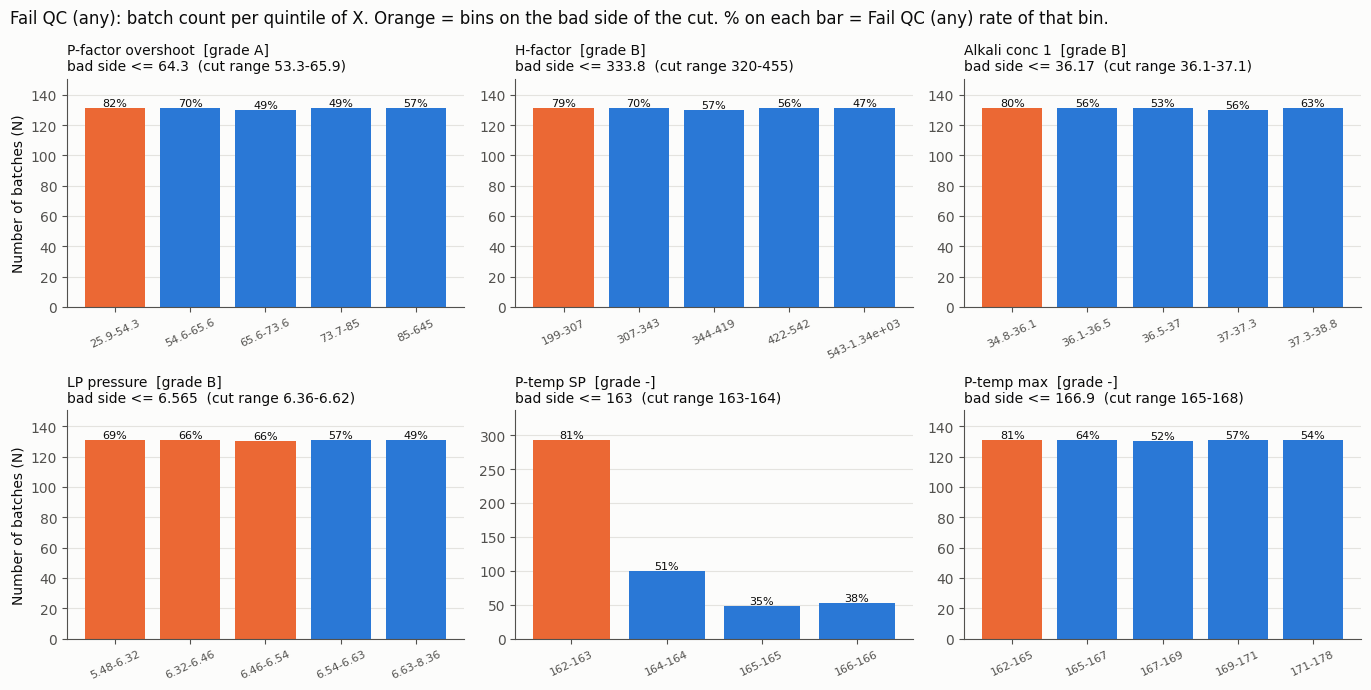

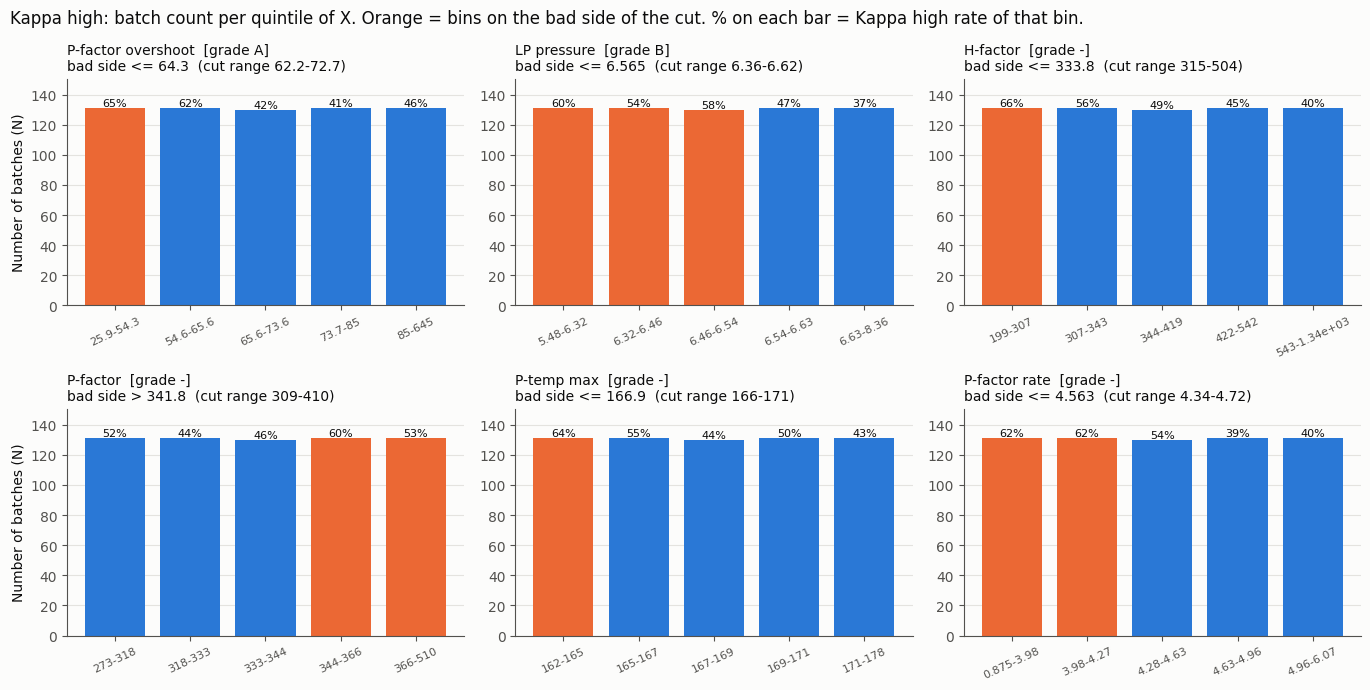

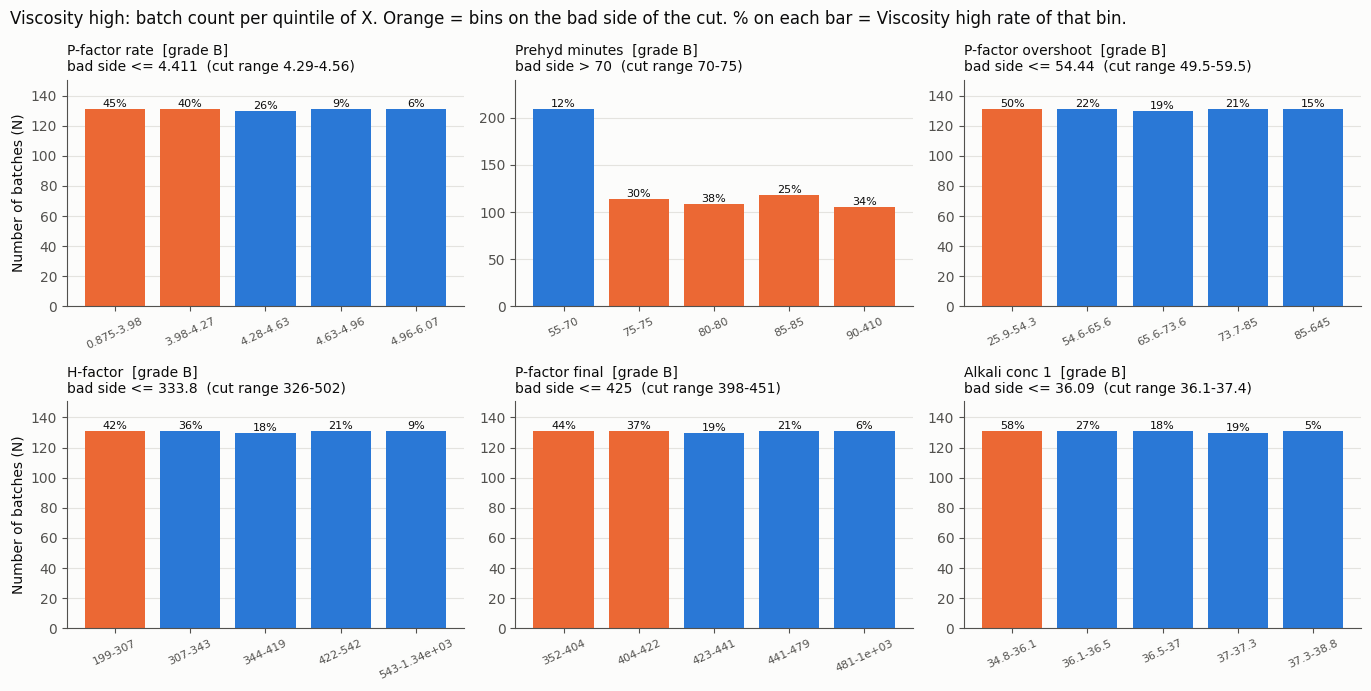

In [42]:
for event in ["fail", "kappa_high", "visc_high"]:
    plots.count_curves(df, results[event], event)


## Step 6 - Operating window
From the grade A/B rows: a bad side `<=` gives a **lower limit** (keep X above), `>` gives an **upper limit**.
`data_p5 / data_p95` = the range the plant really ran. Where a side has no evidence (e.g. no over-cooking
limit, because Viscosity-low fails are rare), **stay inside the data range** - the data cannot speak beyond it.

In [43]:
win = golden.window(results, df)
win.round(3)

,X,keep_above,lower_from,keep_at_or_below,upper_from,conflict,data_p5,data_p95
pfactor_overshoot,P-factor overshoot,64.300,Fail QC (any) (A),NaN,,False,39.036,134.189
h_factor,H-factor,333.824,Fail QC (any) (B),NaN,,False,266.829,734.547
alkali_accumulator1_conc_mean_hot_liquor_filling,Alkali conc 1,36.173,Fail QC (any) (B),NaN,,False,35.662,38.020
LP_pressure_mean_heat_and_cook,LP pressure,6.565,Fail QC (any) (B),NaN,,False,6.024,6.872
pfactor_rate,P-factor rate,4.411,Viscosity high (B),NaN,,False,3.643,5.284
prehydrolysis_minutes,Prehyd minutes,NaN,,70.0,Viscosity high (B),False,65.000,100.000
pfactor_final,P-factor final,424.969,Viscosity high (B),NaN,,False,375.586,540.845
pfactor_actual_last_prehydrolysis,P-factor,354.764,Viscosity high (B),NaN,,False,300.761,423.914
heat_and_cook_minutes,H&C minutes,35.000,Viscosity high (B),NaN,,False,25.000,45.000
pfactor_temp_max_prehydrolysis,P-temp max,166.171,Viscosity high (B),NaN,,False,163.156,173.101


### Combined window check
Rules from `config.GOLDEN_WINDOW_RULES`. A batch is **inside** when it meets every rule.
This is the test of the window itself: fail rate inside vs outside, overall and **month by month**.

Rules: [('pfactor_overshoot', '>', 64.3), ('h_factor', '>', 333.8)]
Fail QC (any)   inside 298 (46%) | fail inside 46% (0.4, 0.52) vs outside 75% (0.7, 0.79) | Fisher p 6.7e-14 | MH RR outside 1.35 (p 0.000) | months 6/6
Kappa high      inside 298 (46%) | fail inside 39% (0.33, 0.44) vs outside 62% (0.57, 0.67) | Fisher p 3.5e-09 | MH RR outside 1.36 (p 0.000) | months 6/6
Viscosity high  inside 298 (46%) | fail inside 13% (0.1, 0.17) vs outside 36% (0.31, 0.41) | Fisher p 2.5e-11 | MH RR outside 1.93 (p 0.000) | months 4/6
Viscosity low   inside 298 (46%) | fail inside 2% (0.01, 0.05) vs outside 4% (0.02, 0.06) | Fisher p 2.7e-01 | MH RR outside 1.32 (p 0.512) | months 3/6
  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\golden_window_months.png


,month,n_outside,fail_outside,n_inside,fail_inside
0,2026-05,12,0.58,54,0.30
1,2026-06,24,0.38,73,0.26
2,2026-07,71,0.80,40,0.55
3,2026-08,87,0.87,51,0.65
4,2026-09,103,0.82,50,0.64
5,2026-10,59,0.56,30,0.50


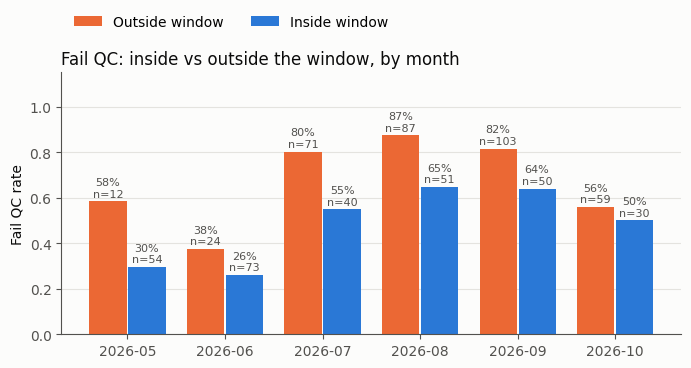

In [44]:
print("Rules:", config.GOLDEN_WINDOW_RULES)
for event in ["fail", "kappa_high", "visc_high", "visc_low"]:
    s, pm = golden.window_check(df, config.GOLDEN_WINDOW_RULES, event)
    print(f"{golden.OUTCOMES[event]:15s} inside {s['n_inside']} ({s['share_inside']:.0%}) | "
          f"fail inside {s['fail_inside']:.0%} {tuple(round(v, 2) for v in s['fail_inside_ci'])} vs "
          f"outside {s['fail_outside']:.0%} {tuple(round(v, 2) for v in s['fail_outside_ci'])} | "
          f"Fisher p {s['fisher_p']:.1e} | MH RR outside {s['mh_rr_outside']:.2f} (p {s['mh_p']:.3f}) | months {s['months_agree']}")

s, pm = golden.window_check(df, config.GOLDEN_WINDOW_RULES, "fail")
plots.window_months(pm, "Fail QC: inside vs outside the window, by month");
pm.round(2)

## Reading the result
- **Grade A** -> propose a trial / SOP candidate. **B** -> trial to confirm. **C / -** -> do not adjust on this evidence.
- A window says *where the fail rate is lower in history*, not that moving X **causes** it. Check the chemistry, then confirm with a trial (e.g. same week, alternate the setting).
- Viscosity-low fails are rare, so the data has **no upper limit** for cooking strength: never push X beyond `data_p95`.
- Log each run in `update.md`.

## Scatter - P-factor overshoot vs Viscosity
Each dot = one batch. Blue band = Viscosity spec. Dashed line = cut from the screen. Change `X_COL` to look at another X.

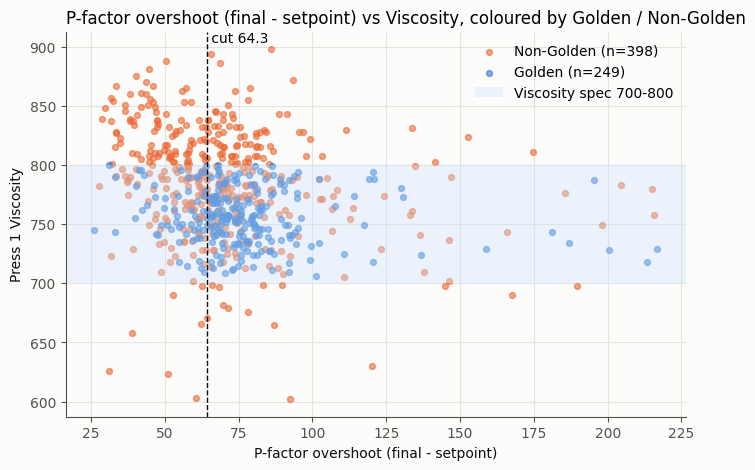

Spearman overshoot vs Viscosity: -0.26


In [45]:
import matplotlib.pyplot as plt

X_COL, X_LABEL = "pfactor_overshoot", "P-factor overshoot (final - setpoint)"
CUT = 64.3                                          # cut from the golden screen
v_lo, v_hi = config.GOLDEN_SPEC["press1_viscosity"]

d = df[df[X_COL] <= df[X_COL].quantile(0.99)]       # hide the top 1% (up to ~600) so the plot is readable
fig, ax = plt.subplots(figsize=(8, 5))
for flag, name, color in [(0, "Non-Golden", "#eb6834"), (1, "Golden", "#2a78d6")]:
    s = d[d["golden"] == flag]
    ax.scatter(s[X_COL], s["press1_viscosity"], s=18, alpha=0.6, color=color, label=f"{name} (n={len(s)})")
ax.axhspan(v_lo, v_hi, color="#cde2fb", alpha=0.35, lw=0, label=f"Viscosity spec {v_lo}-{v_hi}")
ax.axvline(CUT, color="#0b0b0b", ls="--", lw=1)
ax.text(CUT, ax.get_ylim()[1], f" cut {CUT}", va="top")
ax.set_xlabel(X_LABEL)
ax.set_ylabel("Press 1 Viscosity")
ax.set_title(f"{X_LABEL} vs Viscosity, coloured by Golden / Non-Golden", loc="left")
ax.legend(frameon=False, loc="upper right")
plt.show()
print(f"Spearman overshoot vs Viscosity: {df[[X_COL, 'press1_viscosity']].corr(method='spearman').iloc[0, 1]:+.2f}")